In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, zipfile, random, json, pickle, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Google Drive folders
DATA_DIR = Path("/content/drive/MyDrive/DATA")
OUT_DIR = DATA_DIR / "combined_run"
PROC_DIR = OUT_DIR / "processed"
MODEL_DIR = OUT_DIR / "models"
FIG_DIR = OUT_DIR / "figures"

for folder in [OUT_DIR, PROC_DIR, MODEL_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Assignment parameters
TARGETS = ["p (mbar)", "T (degC)", "rh (%)", "wv (m/s)"]

K = 6
TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

BATCH_SIZE = 64
LEARNING_RATE = 0.001
MAX_EPOCHS = 50
PATIENCE = 7
HORIZON = 6

# Find ZIP files
zip_paths = sorted(DATA_DIR.glob("*.zip"))

if not zip_paths:
    raise FileNotFoundError("No ZIP files found in MyDrive/DATA")

print("ZIP files found:", len(zip_paths))

def normalize_col(c):
    return re.sub(r"\s+", " ", str(c).strip())

frames = []
inventory = []

# Read all CSV/TXT files inside ZIP files
for zp in zip_paths:

    with zipfile.ZipFile(zp, "r") as zf:

        members = [
            x for x in zf.namelist()
            if x.lower().endswith((".csv", ".txt"))
        ]

        for member in members:

            try:
                with zf.open(member) as f:
                    df = pd.read_csv(f, sep=";", low_memory=False)

                    if df.shape[1] <= 1:
                        f.seek(0)
                        df = pd.read_csv(f, sep=",", low_memory=False)

                df.columns = [normalize_col(c) for c in df.columns]

                frames.append(df)

                inventory.append({
                    "ZIP": zp.name,
                    "File": member,
                    "Rows": len(df)
                })

            except Exception as e:
                print("File reading error:", member, e)

if not frames:
    raise RuntimeError("No CSV data could be read.")

raw = pd.concat(frames, ignore_index=True, sort=False)

print("\nRaw rows:", len(raw))
print("Available columns:")
print(list(raw.columns))

pd.DataFrame(inventory).to_csv(
    PROC_DIR / "input_file_inventory.csv", index=False
)

Mounted at /content/drive
Device: cpu
ZIP files found: 16

Raw rows: 419515
Available columns:
['Date Time', 'p (mbar)', 'T (degC)', 'rh (%)', 'sh (g/kg)', 'Tpot (K)', 'Tdew (degC)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'wd (deg)', 'rain (mm)', 'SWDR (W/m**2)', 'SDUR (s)', 'TRAD (degC)', 'Rn (W/m**2)', 'ST002 (degC)', 'ST004 (degC)', 'ST008 (degC)', 'ST016 (degC)', 'ST032 (degC)', 'ST064 (degC)', 'ST128 (degC)', 'SM008 (%)', 'SM016 (%)', 'SM032 (%)', 'SM064 (%)', 'SM128 (%)']


In [3]:
def find_column(columns, candidates):

    lookup = {str(c).strip().lower(): c for c in columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    return None


# Identify timestamp column
date_col = find_column(
    raw.columns,
    ["Date Time", "datetime", "date_time", "timestamp", "date"]
)

if date_col is None:
    raise KeyError("Timestamp column not identified. Check the column names.")

# Identify weather columns
column_aliases = {
    "p (mbar)": ["p (mbar)", "p", "pressure"],
    "T (degC)": ["T (degC)", "T", "temperature"],
    "rh (%)": ["rh (%)", "rh", "relative humidity"],
    "wv (m/s)": ["wv (m/s)", "wv", "wind velocity", "wind speed"]
}

rename_map = {}

for target, aliases in column_aliases.items():

    found = find_column(raw.columns, aliases)

    if found is None:
        raise KeyError(
            f"Missing {target}. Available columns: {list(raw.columns)}"
        )

    rename_map[found] = target


data = raw[[date_col] + list(rename_map.keys())].rename(
    columns={date_col: "Date Time", **rename_map}
).copy()

# Parse date and time
data["Date Time"] = pd.to_datetime(
    data["Date Time"], errors="coerce", dayfirst=True
)

invalid_dates = int(data["Date Time"].isna().sum())

data = data.dropna(subset=["Date Time"]).copy()

# Convert measurements to numerical values
for col in TARGETS:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Keep 2009-2016
before_year_filter = len(data)

data = data[
    (data["Date Time"].dt.year >= 2009) &
    (data["Date Time"].dt.year <= 2016)
].copy()

year_mismatch_removed = before_year_filter - len(data)

# Remove exact duplicates
before_duplicates = len(data)

data = data.drop_duplicates(
    subset=["Date Time"] + TARGETS
)

exact_duplicates_removed = before_duplicates - len(data)

# Count repeated timestamps before aggregation
repeated_timestamp_rows = int(
    data.duplicated(subset=["Date Time"], keep=False).sum()
)

# Average repeated timestamp measurements
ten_minute = (
    data.groupby("Date Time")[TARGETS]
    .mean()
    .sort_index()
)

# Convert to hourly measurements
hourly_observed = ten_minute.resample("1h").mean()

# Create complete hourly timeline
full_index = pd.date_range(
    start=hourly_observed.index.min().floor("h"),
    end=hourly_observed.index.max().floor("h"),
    freq="1h"
)

hourly = hourly_observed.reindex(full_index)
hourly.index.name = "Date Time"

missing_hours = int(
    hourly[TARGETS].isna().any(axis=1).sum()
)

complete_hourly = hourly.dropna(subset=TARGETS)

# Save preprocessing data
hourly.reset_index().to_csv(
    PROC_DIR / "hourly_weather_with_missing.csv", index=False
)

complete_hourly.reset_index().to_csv(
    PROC_DIR / "hourly_weather_complete.csv", index=False
)

preprocess_summary = {
    "ZIP_files": len(zip_paths),
    "raw_rows": len(raw),
    "invalid_dates_removed": invalid_dates,
    "year_mismatches_removed": year_mismatch_removed,
    "exact_duplicates_removed": exact_duplicates_removed,
    "rows_after_timestamp_aggregation": len(ten_minute),
    "repeated_timestamp_rows": repeated_timestamp_rows,
    "hourly_timeline_rows": len(hourly),
    "missing_hour_rows": missing_hours,
    "complete_hourly_rows": len(complete_hourly),
    "first_hour": str(hourly.index.min()),
    "last_hour": str(hourly.index.max())
}

with open(PROC_DIR / "preprocessing_summary.json", "w") as f:
    json.dump(preprocess_summary, f, indent=2)

print("\n========== PREPROCESSING SUMMARY ==========")

for key, value in preprocess_summary.items():
    print(key, ":", value)


========== PREPROCESSING SUMMARY ==========
ZIP_files : 16
raw_rows : 419515
invalid_dates_removed : 0
year_mismatches_removed : 1
exact_duplicates_removed : 27
rows_after_timestamp_aggregation : 419476
repeated_timestamp_rows : 22
hourly_timeline_rows : 70128
missing_hour_rows : 202
complete_hourly_rows : 69926
first_hour : 2009-01-01 00:00:00
last_hour : 2016-12-31 23:00:00


In [4]:
# Chronological split
n = len(hourly)

train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

split_frames = {
    "train": hourly.iloc[:train_end].copy(),
    "validation": hourly.iloc[train_end:val_end].copy(),
    "test": hourly.iloc[val_end:].copy()
}

# Fit scaler ONLY on training data
scaler = StandardScaler()

train_complete = split_frames["train"].dropna(subset=TARGETS)

if len(train_complete) == 0:
    raise RuntimeError("No complete training observations.")

scaler.fit(train_complete[TARGETS].values)

with open(PROC_DIR / "weather_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)


def make_sequences(frame):

    values = frame[TARGETS].values.astype(float)
    times = frame.index

    scaled = np.full(values.shape, np.nan)

    valid_rows = np.isfinite(values).all(axis=1)

    scaled[valid_rows] = scaler.transform(values[valid_rows])

    X_list = []
    y_list = []
    y_times = []

    for i in range(K, len(frame)):

        window = scaled[i-K:i]
        target = scaled[i]

        if not np.isfinite(window).all():
            continue

        if not np.isfinite(target).all():
            continue

        # Ensure six consecutive hourly inputs and target
        time_window = times[i-K:i+1]

        differences = np.diff(
            time_window.values
        ).astype("timedelta64[m]").astype(int)

        if not np.all(differences == 60):
            continue

        X_list.append(window)
        y_list.append(target)
        y_times.append(times[i])

    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(y_list, dtype=np.float32),
        pd.DatetimeIndex(y_times)
    )


sequences = {}

for name, frame in split_frames.items():

    sequences[name] = make_sequences(frame)

    Xs, ys, ts = sequences[name]

    print(
        name,
        "X shape:", Xs.shape,
        "y shape:", ys.shape
    )


X_train, y_train, train_times = sequences["train"]
X_val, y_val, val_times = sequences["validation"]
X_test, y_test, test_times = sequences["test"]

if min(len(X_train), len(X_val), len(X_test)) == 0:
    raise RuntimeError("A split contains no valid sequences.")

sequence_summary = {
    "K": K,
    "train_sequences": len(X_train),
    "validation_sequences": len(X_val),
    "test_sequences": len(X_test),
    "total_sequences": len(X_train) + len(X_val) + len(X_test),
    "X_train_shape": list(X_train.shape),
    "X_validation_shape": list(X_val.shape),
    "X_test_shape": list(X_test.shape)
}

with open(PROC_DIR / "sequence_summary.json", "w") as f:
    json.dump(sequence_summary, f, indent=2)

print("\n========== SEQUENCE SUMMARY ==========")
print(json.dumps(sequence_summary, indent=2))

np.savez_compressed(
    PROC_DIR / "weather_sequences.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test,
    test_times=test_times.astype(str)
)

train X shape: (48822, 6, 4) y shape: (48822, 4)
validation X shape: (10500, 6, 4) y shape: (10500, 4)
test X shape: (10514, 6, 4) y shape: (10514, 4)

========== SEQUENCE SUMMARY ==========
{
  "K": 6,
  "train_sequences": 48822,
  "validation_sequences": 10500,
  "test_sequences": 10514,
  "total_sequences": 69836,
  "X_train_shape": [
    48822,
    6,
    4
  ],
  "X_validation_shape": [
    10500,
    6,
    4
  ],
  "X_test_shape": [
    10514,
    6,
    4
  ]
}


In [5]:
class MLPModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(K * 4, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 4)
        )

    def forward(self, x):
        x = x.reshape(x.size(0), -1)
        return self.net(x)


class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=64,
            batch_first=True
        )

        self.fc1 = nn.Linear(64, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 4)

    def forward(self, x):

        output, _ = self.lstm(x)

        last = output[:, -1, :]

        x = self.fc1(last)
        x = self.relu(x)

        return self.fc2(x)


class CNNModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=4,
            out_channels=32,
            kernel_size=2
        )

        self.conv2 = nn.Conv1d(
            in_channels=32,
            out_channels=64,
            kernel_size=2
        )

        self.relu = nn.ReLU()

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(64, 4)

    def forward(self, x):

        # (batch, time, features) -> (batch, features, time)
        x = x.transpose(1, 2)

        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        x = self.pool(x).squeeze(-1)

        return self.fc(x)


model_factories = {
    "MLP": MLPModel,
    "LSTM": LSTMModel,
    "CNN": CNNModel
}

print("Three models defined successfully.")

Three models defined successfully.


In [6]:
def make_loader(X, y, shuffle):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


train_loader = make_loader(X_train, y_train, True)
val_loader = make_loader(X_val, y_val, False)


def train_model(name, model):

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.MSELoss()

    best_val = float("inf")
    best_state = None
    patience_counter = 0

    history = []

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        train_losses = []

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            prediction = model(xb)

            loss = criterion(prediction, yb)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # Validation
        model.eval()
        val_losses = []

        with torch.no_grad():

            for xb, yb in val_loader:

                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                prediction = model(xb)

                loss = criterion(prediction, yb)

                val_losses.append(loss.item())

        train_loss = np.mean(train_losses)
        val_loss = np.mean(val_losses)

        history.append({
            "epoch": epoch,
            "train_mse": train_loss,
            "validation_mse": val_loss
        })

        print(
            f"{name} | Epoch {epoch} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Validation MSE: {val_loss:.6f}"
        )

        if val_loss < best_val:

            best_val = val_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

            patience_counter = 0

        else:

            patience_counter += 1

            if patience_counter >= PATIENCE:
                print("Early stopping:", name)
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    torch.save(
        model.state_dict(),
        MODEL_DIR / f"{name.lower()}_best.pt"
    )

    pd.DataFrame(history).to_csv(
        OUT_DIR / f"{name.lower()}_training_history.csv",
        index=False
    )

    return model


models = {}

for name, factory in model_factories.items():

    print("\n========== TRAINING", name, "==========")

    model = factory()

    models[name] = train_model(name, model)

print("\nAll models trained.")


========== TRAINING MLP ==========
MLP | Epoch 1 | Train MSE: 0.549237 | Validation MSE: 0.005508
MLP | Epoch 2 | Train MSE: 0.341575 | Validation MSE: 0.005179
MLP | Epoch 3 | Train MSE: 0.312639 | Validation MSE: 0.006064
MLP | Epoch 4 | Train MSE: 0.299690 | Validation MSE: 0.005931
MLP | Epoch 5 | Train MSE: 0.301145 | Validation MSE: 0.005782
MLP | Epoch 6 | Train MSE: 0.285688 | Validation MSE: 0.006529
MLP | Epoch 7 | Train MSE: 0.291607 | Validation MSE: 0.006241
MLP | Epoch 8 | Train MSE: 0.287429 | Validation MSE: 0.006040
MLP | Epoch 9 | Train MSE: 0.279837 | Validation MSE: 0.006107
Early stopping: MLP

========== TRAINING LSTM ==========
LSTM | Epoch 1 | Train MSE: 0.673533 | Validation MSE: 0.005713
LSTM | Epoch 2 | Train MSE: 0.364070 | Validation MSE: 0.007828
LSTM | Epoch 3 | Train MSE: 0.301667 | Validation MSE: 0.008900
LSTM | Epoch 4 | Train MSE: 0.277778 | Validation MSE: 0.007546
LSTM | Epoch 5 | Train MSE: 0.264808 | Validation MSE: 0.005675
LSTM | Epoch 6 | Tra

In [7]:
def predict_scaled(model, X):

    model.eval()
    outputs = []

    with torch.no_grad():

        for start in range(0, len(X), BATCH_SIZE):

            xb = torch.tensor(
                X[start:start+BATCH_SIZE],
                dtype=torch.float32
            ).to(DEVICE)

            outputs.append(model(xb).cpu().numpy())

    return np.concatenate(outputs, axis=0)


def inverse_scale(arr):
    return scaler.inverse_transform(arr)


y_test_original = inverse_scale(y_test)

individual_rows = []
overall_rows = []
prediction_frames = []

for name, model in models.items():

    pred_scaled = predict_scaled(model, X_test)
    pred_original = inverse_scale(pred_scaled)

    # Feature-wise metrics
    for j, feature in enumerate(TARGETS):

        mae = mean_absolute_error(
            y_test_original[:, j],
            pred_original[:, j]
        )

        rmse = np.sqrt(mean_squared_error(
            y_test_original[:, j],
            pred_original[:, j]
        ))

        r2 = r2_score(
            y_test_original[:, j],
            pred_original[:, j]
        )

        individual_rows.append({
            "Model": name,
            "Feature": feature,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    # Overall metrics
    overall_rows.append({
        "Model": name,

        "Overall_MAE": mean_absolute_error(
            y_test_original,
            pred_original,
            multioutput="uniform_average"
        ),

        "Overall_RMSE": np.sqrt(
            np.mean((y_test_original - pred_original) ** 2)
        ),

        "Average_R2": r2_score(
            y_test_original,
            pred_original,
            multioutput="uniform_average"
        )
    })

    # Save actual and predicted values
    result = pd.DataFrame({
        "Date Time": test_times
    })

    for j, feature in enumerate(TARGETS):

        result[f"Actual_{feature}"] = y_test_original[:, j]
        result[f"Predicted_{feature}"] = pred_original[:, j]

    result["Model"] = name

    prediction_frames.append(result)


individual_df = pd.DataFrame(individual_rows)
overall_df = pd.DataFrame(overall_rows)

predictions_df = pd.concat(
    prediction_frames,
    ignore_index=True
)

individual_df.to_csv(
    OUT_DIR / "individual_model_results.csv",
    index=False
)

overall_df.to_csv(
    OUT_DIR / "overall_model_results.csv",
    index=False
)

predictions_df.to_csv(
    OUT_DIR / "test_predictions.csv",
    index=False
)

print("\n========== FEATURE-WISE RESULTS ==========")
print(individual_df.round(4).to_string(index=False))

print("\n========== OVERALL RESULTS ==========")
print(overall_df.round(4).to_string(index=False))


========== FEATURE-WISE RESULTS ==========
Model  Feature     MAE    RMSE      R2
  MLP p (mbar)  4.7900  7.1087  0.3697
  MLP T (degC)  3.2523  5.9375  0.4235
  MLP   rh (%)  7.7686 12.4133  0.5381
  MLP wv (m/s)  8.4443 48.0964 -0.0948
 LSTM p (mbar)  6.8631  8.8271  0.0281
 LSTM T (degC)  4.4842  6.0946  0.3926
 LSTM   rh (%)  6.2444  8.8286  0.7664
 LSTM wv (m/s)  2.1289 50.5283 -0.2083
  CNN p (mbar)  4.1711  4.9487  0.6945
  CNN T (degC)  5.1114  6.5336  0.3020
  CNN   rh (%) 11.1607 15.9659  0.2359
  CNN wv (m/s)  6.1903 46.1807 -0.0093

========== OVERALL RESULTS ==========
Model  Overall_MAE  Overall_RMSE  Average_R2
  MLP       6.0638     25.264299      0.3091
 LSTM       4.9302     26.201700      0.2447
  CNN       6.6584     24.772699      0.3058


In [8]:
recursive_feature_rows = []
recursive_overall_rows = []

# Select test origins having six consecutive hourly targets
valid_origins = []

for i in range(len(test_times) - HORIZON + 1):

    expected = pd.date_range(
        test_times[i],
        periods=HORIZON,
        freq="1h"
    )

    actual_times = test_times[i:i+HORIZON]

    if np.array_equal(actual_times.values, expected.values):
        valid_origins.append(i)

print("Recursive forecast origins:", len(valid_origins))

if not valid_origins:
    raise RuntimeError("No contiguous six-hour test sequences found.")


for name, model in models.items():

    horizon_actual = [[] for _ in range(HORIZON)]
    horizon_pred = [[] for _ in range(HORIZON)]

    model.eval()

    with torch.no_grad():

        for origin in valid_origins:

            # Start with six actual observations
            rolling = X_test[origin].copy()

            for h in range(HORIZON):

                xb = torch.tensor(
                    rolling[None, :, :],
                    dtype=torch.float32
                ).to(DEVICE)

                pred_scaled = model(xb).cpu().numpy()[0]

                actual_scaled = y_test[origin + h]

                horizon_pred[h].append(pred_scaled)
                horizon_actual[h].append(actual_scaled)

                # Feed prediction into the next time step
                rolling = np.vstack([
                    rolling[1:],
                    pred_scaled
                ])

    # Calculate metrics at every forecast horizon
    for h in range(HORIZON):

        ya = inverse_scale(
            np.asarray(horizon_actual[h])
        )

        yp = inverse_scale(
            np.asarray(horizon_pred[h])
        )

        for j, feature in enumerate(TARGETS):

            recursive_feature_rows.append({

                "Model": name,
                "Horizon_hours": h + 1,
                "Feature": feature,

                "MAE": mean_absolute_error(
                    ya[:, j], yp[:, j]
                ),

                "RMSE": np.sqrt(
                    mean_squared_error(ya[:, j], yp[:, j])
                ),

                "R2": r2_score(
                    ya[:, j], yp[:, j]
                )
            })

        recursive_overall_rows.append({

            "Model": name,
            "Horizon_hours": h + 1,

            "Overall_MAE": mean_absolute_error(
                ya, yp, multioutput="uniform_average"
            ),

            "Overall_RMSE": np.sqrt(
                np.mean((ya - yp) ** 2)
            ),

            "Average_R2": r2_score(
                ya, yp, multioutput="uniform_average"
            )
        })


recursive_feature_df = pd.DataFrame(recursive_feature_rows)
recursive_overall_df = pd.DataFrame(recursive_overall_rows)

recursive_feature_df.to_csv(
    OUT_DIR / "error_propagation_by_feature.csv",
    index=False
)

recursive_overall_df.to_csv(
    OUT_DIR / "error_propagation_overall.csv",
    index=False
)

print("\n========== RECURSIVE FEATURE RESULTS ==========")
print(recursive_feature_df.round(4).to_string(index=False))

print("\n========== RECURSIVE OVERALL RESULTS ==========")
print(recursive_overall_df.round(4).to_string(index=False))

Recursive forecast origins: 10509

========== RECURSIVE FEATURE RESULTS ==========
Model  Horizon_hours  Feature     MAE    RMSE      R2
  MLP              1 p (mbar)  4.7884  7.1081  0.3697
  MLP              1 T (degC)  3.2535  5.9389  0.4224
  MLP              1   rh (%)  7.7716 12.4162  0.5379
  MLP              1 wv (m/s)  8.4429 48.1072 -0.0948
  MLP              2 p (mbar)  6.5592  8.9993 -0.0102
  MLP              2 T (degC)  4.7874  7.9761 -0.0415
  MLP              2   rh (%) 12.0125 17.3960  0.0929
  MLP              2 wv (m/s) 12.4681 50.8968 -0.2254
  MLP              3 p (mbar)  8.4638 11.0176 -0.5140
  MLP              3 T (degC)  5.7054  9.1371 -0.3663
  MLP              3   rh (%) 16.9254 22.8052 -0.5590
  MLP              3 wv (m/s) 15.4896 50.3055 -0.1971
  MLP              4 p (mbar)  9.8959 12.5440 -0.9624
  MLP              4 T (degC)  6.3065  9.2910 -0.4121
  MLP              4   rh (%) 21.3720 27.9257 -1.3377
  MLP              4 wv (m/s) 17.5008 51.0992 -0.2352

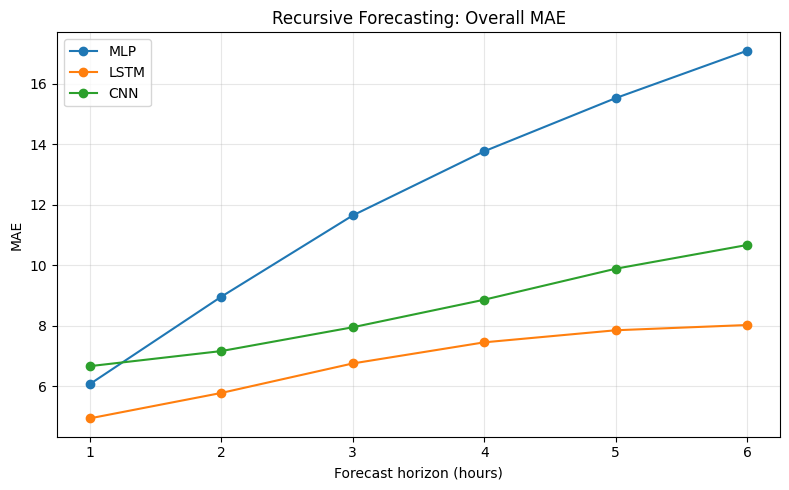

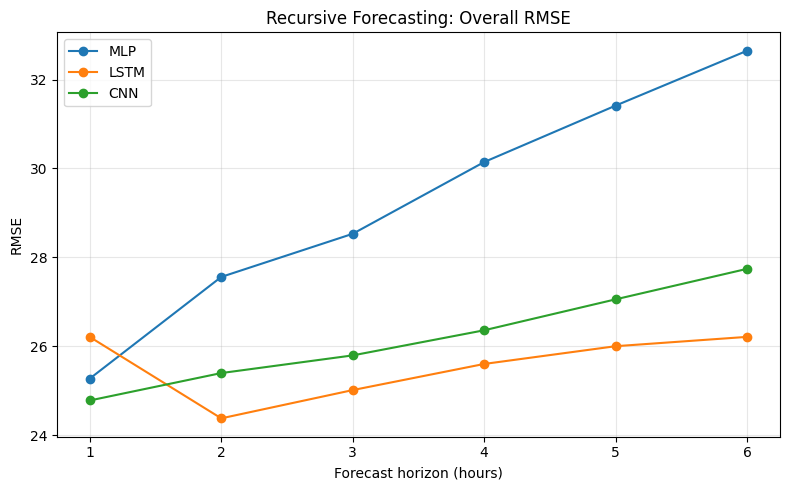

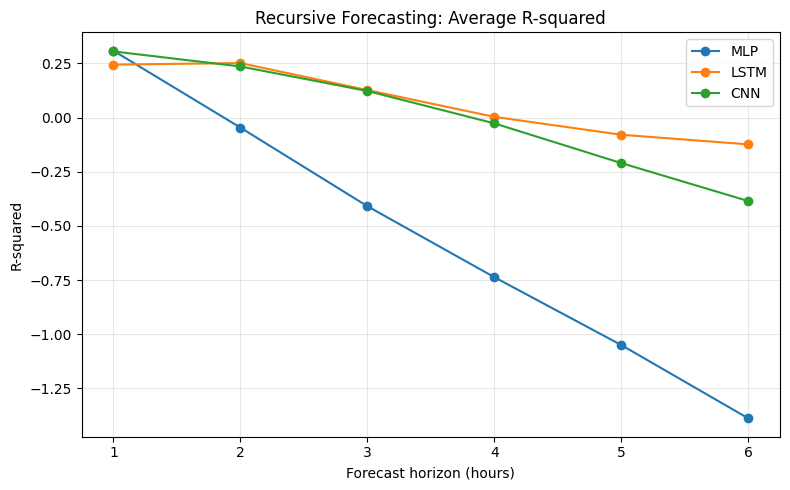

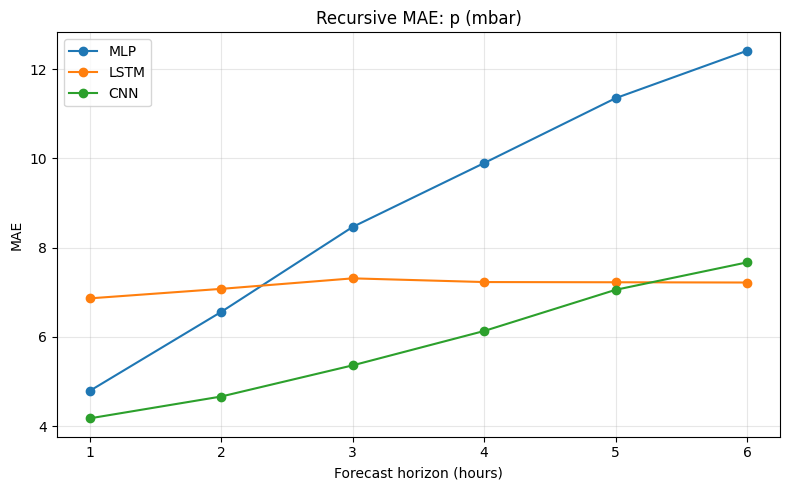

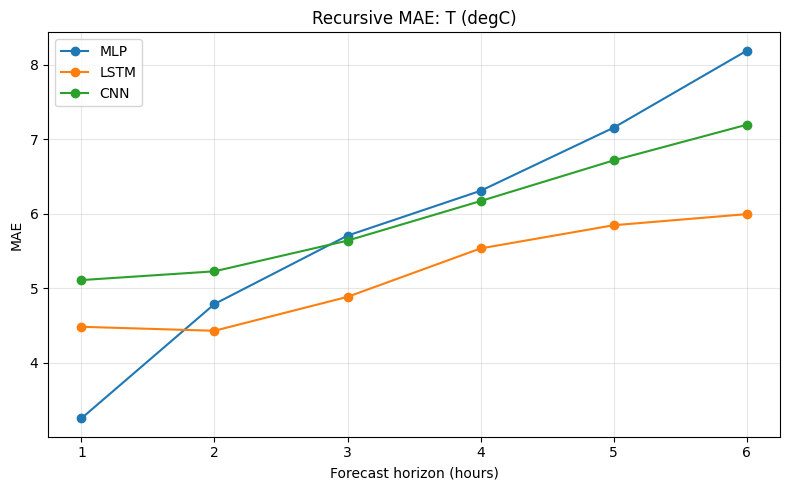

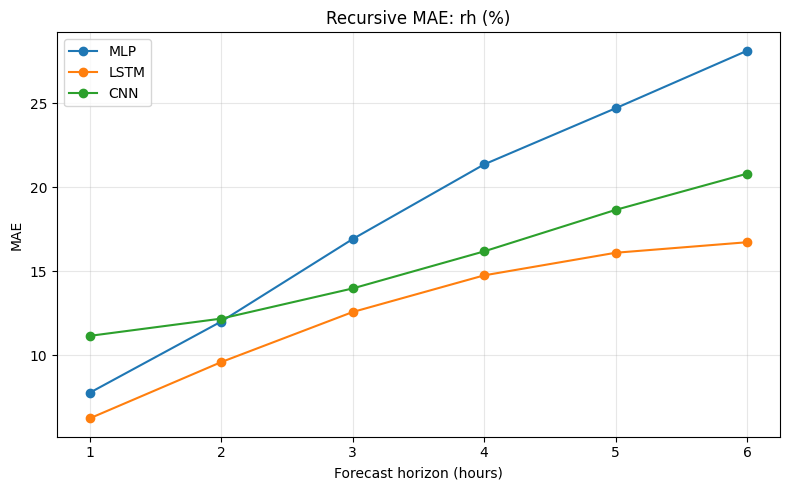

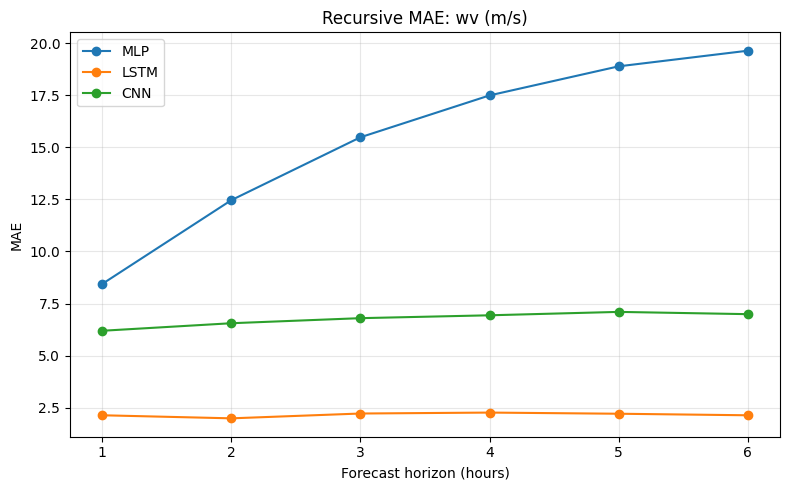

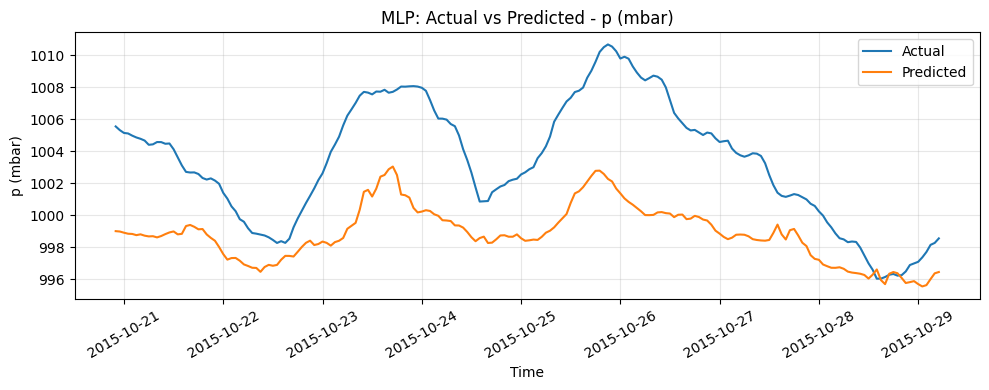

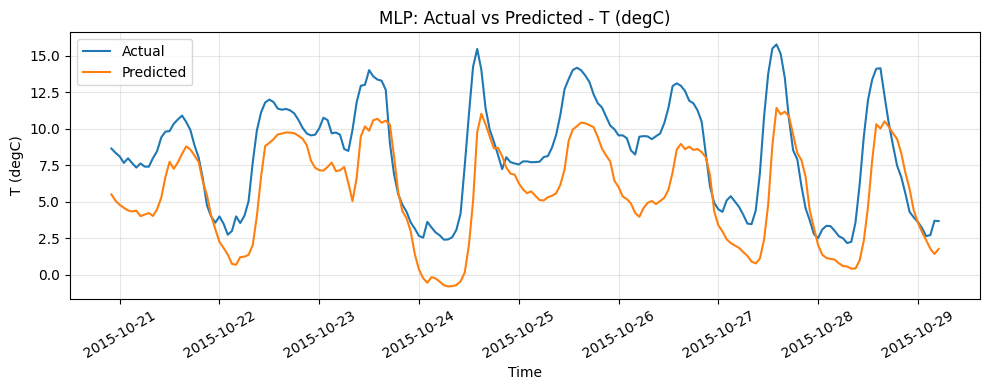

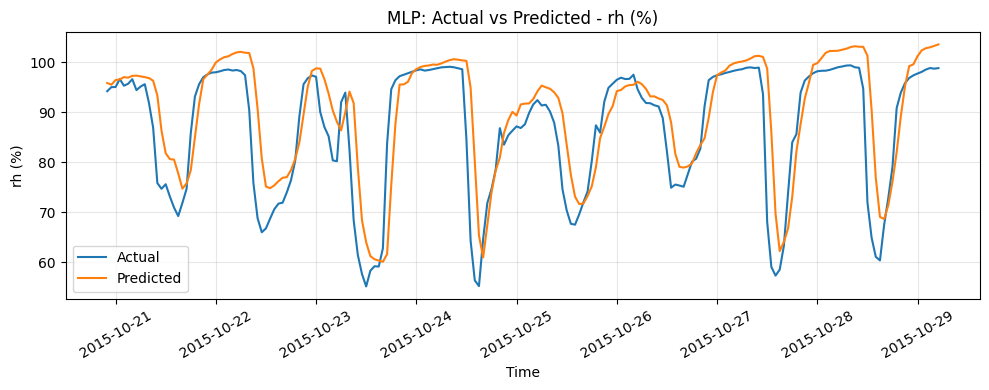

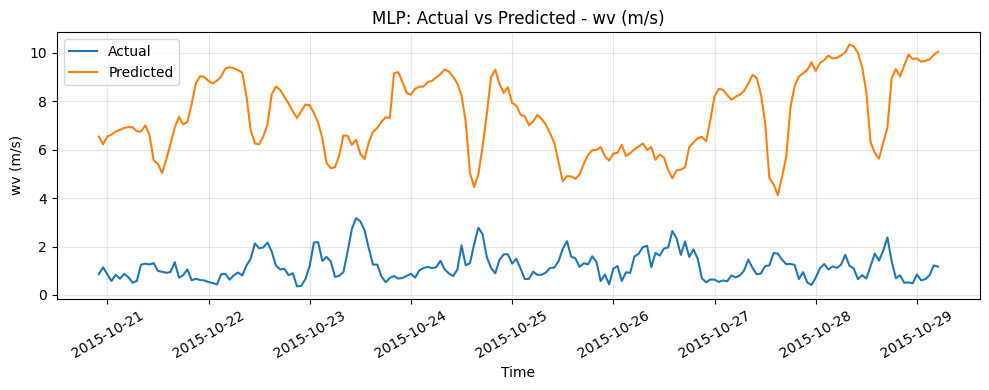

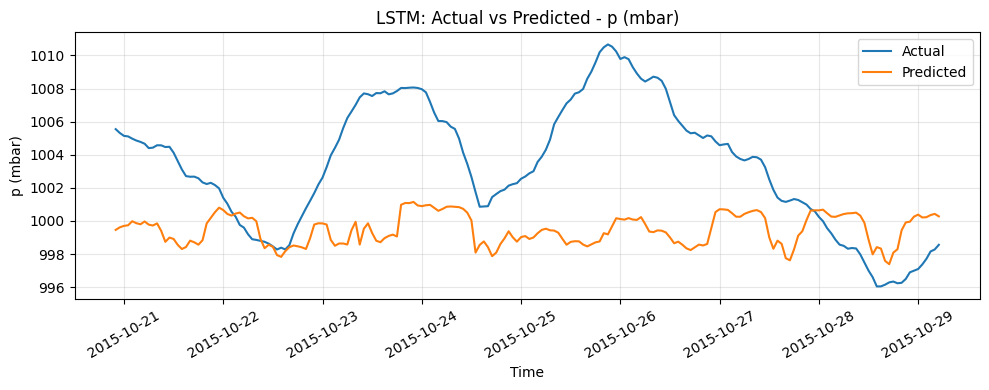

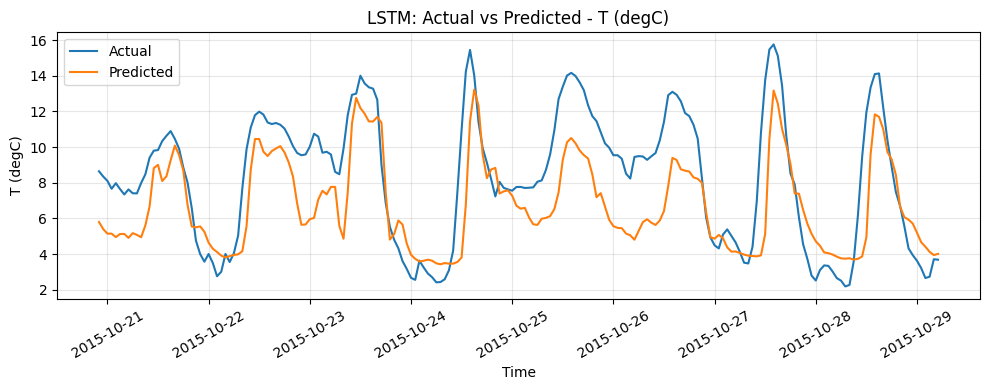

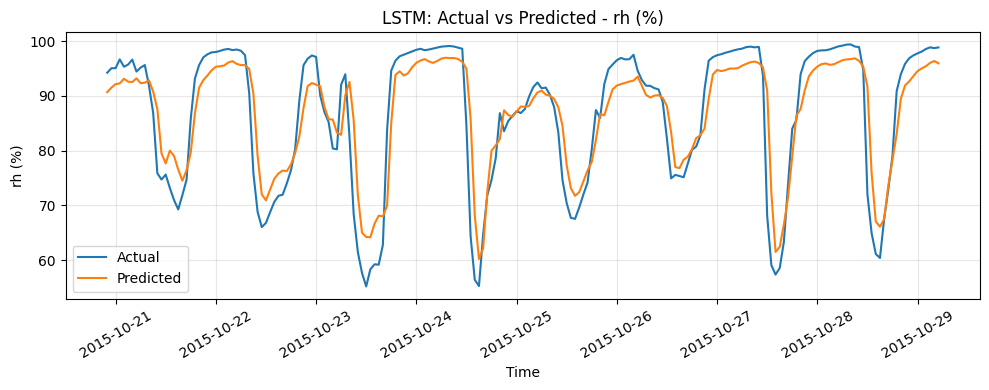

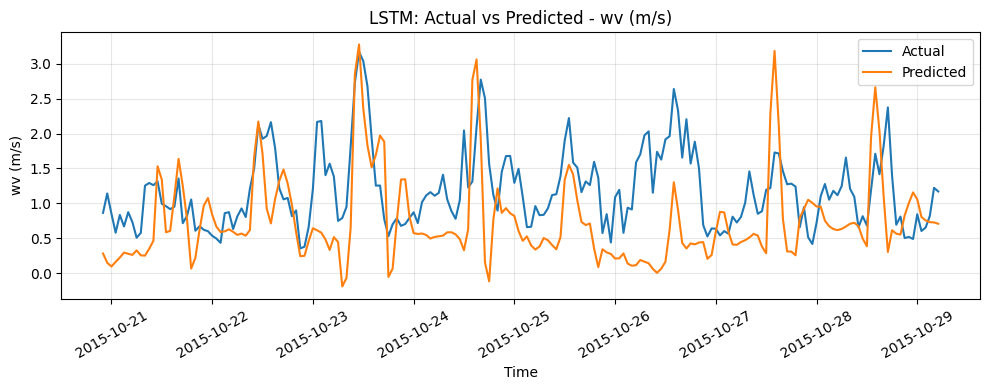

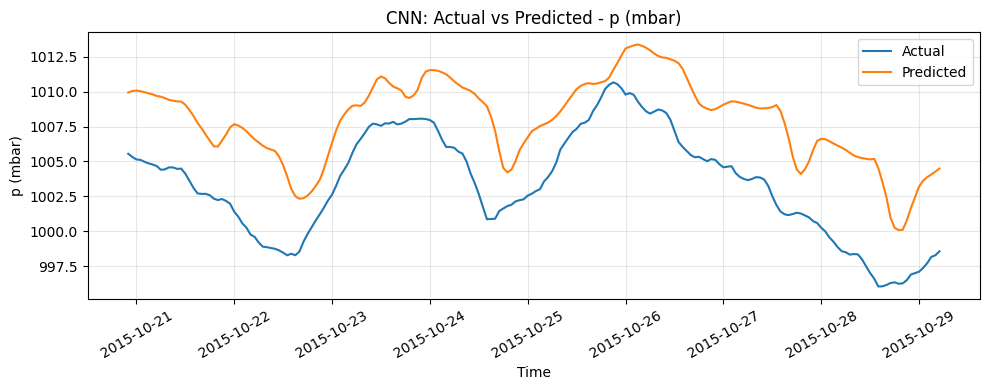

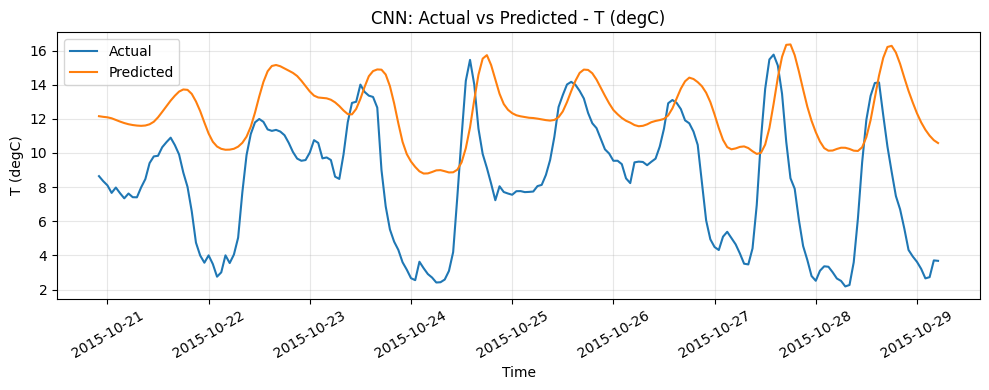

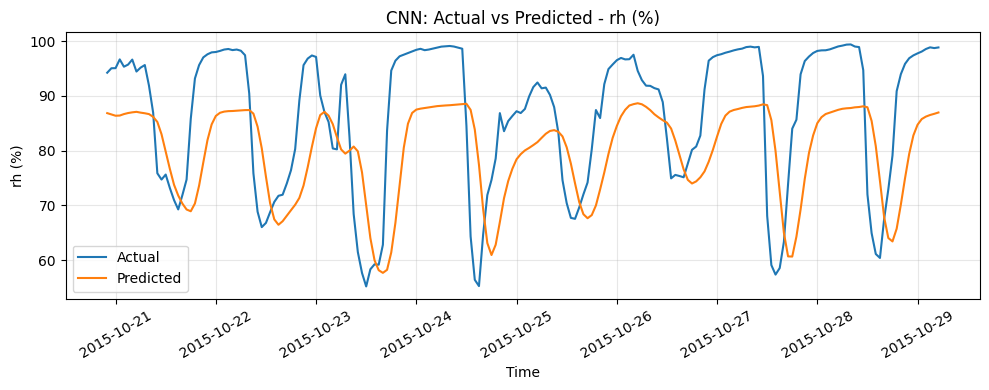

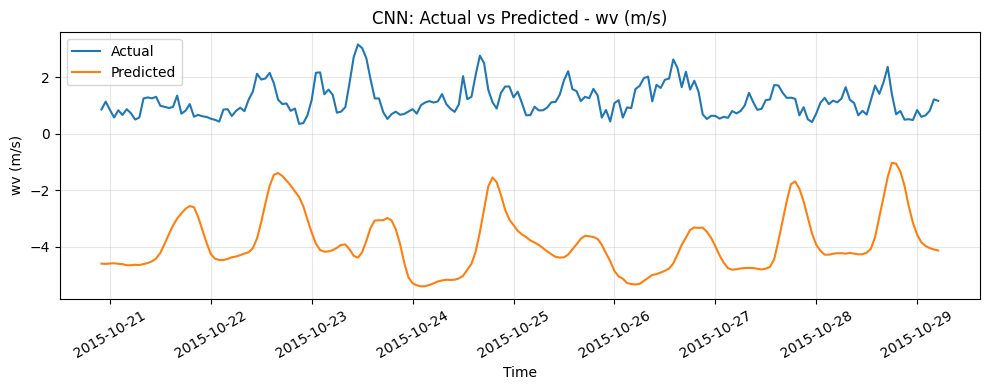

In [9]:
def plot_recursive_metric(metric, title, ylabel, filename):

    plt.figure(figsize=(8, 5))

    for model_name in model_factories:

        sub = recursive_overall_df[
            recursive_overall_df["Model"] == model_name
        ].sort_values("Horizon_hours")

        plt.plot(
            sub["Horizon_hours"],
            sub[metric],
            marker="o",
            label=model_name
        )

    plt.xlabel("Forecast horizon (hours)")
    plt.ylabel(ylabel)
    plt.title(title)

    plt.xticks(range(1, HORIZON + 1))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(FIG_DIR / filename, dpi=300)
    plt.show()
    plt.close()


plot_recursive_metric(
    "Overall_MAE",
    "Recursive Forecasting: Overall MAE",
    "MAE",
    "recursive_overall_mae.png"
)

plot_recursive_metric(
    "Overall_RMSE",
    "Recursive Forecasting: Overall RMSE",
    "RMSE",
    "recursive_overall_rmse.png"
)

plot_recursive_metric(
    "Average_R2",
    "Recursive Forecasting: Average R-squared",
    "R-squared",
    "recursive_overall_r2.png"
)


# Feature-wise recursive MAE plots
for feature in TARGETS:

    sub_all = recursive_feature_df[
        recursive_feature_df["Feature"] == feature
    ]

    plt.figure(figsize=(8, 5))

    for model_name in model_factories:

        sub = sub_all[
            sub_all["Model"] == model_name
        ].sort_values("Horizon_hours")

        plt.plot(
            sub["Horizon_hours"],
            sub["MAE"],
            marker="o",
            label=model_name
        )

    plt.xlabel("Forecast horizon (hours)")
    plt.ylabel("MAE")
    plt.title(f"Recursive MAE: {feature}")

    plt.xticks(range(1, HORIZON + 1))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    safe_name = re.sub(
        r"[^A-Za-z0-9]+", "_", feature
    ).strip("_")

    plt.savefig(
        FIG_DIR / f"recursive_mae_{safe_name}.png",
        dpi=300
    )

    plt.show()
    plt.close()


# Actual vs predicted plots
for name in model_factories:

    sub = predictions_df[
        predictions_df["Model"] == name
    ].head(200)

    for feature in TARGETS:

        plt.figure(figsize=(10, 4))

        plt.plot(
            sub["Date Time"],
            sub[f"Actual_{feature}"],
            label="Actual"
        )

        plt.plot(
            sub["Date Time"],
            sub[f"Predicted_{feature}"],
            label="Predicted"
        )

        plt.xlabel("Time")
        plt.ylabel(feature)
        plt.title(f"{name}: Actual vs Predicted - {feature}")

        plt.xticks(rotation=30)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()

        safe_name = re.sub(
            r"[^A-Za-z0-9]+", "_", feature
        ).strip("_")

        plt.savefig(
            FIG_DIR / f"{name.lower()}_actual_vs_predicted_{safe_name}.png",
            dpi=300
        )

        plt.show()
        plt.close()

In [10]:
print("\n================ FINAL RUN SUMMARY ================")

print("\nPREPROCESSING SUMMARY")
print(json.dumps(preprocess_summary, indent=2))

print("\nSEQUENCE SUMMARY")
print(json.dumps(sequence_summary, indent=2))

print("\nONE-STEP OVERALL RESULTS")
print(overall_df.round(4).to_string(index=False))

print("\nRECURSIVE OVERALL RESULTS")
print(recursive_overall_df.round(4).to_string(index=False))


print("\nFILES GENERATED:")

for path in sorted(OUT_DIR.rglob("*")):

    if path.is_file():

        print(
            path.relative_to(OUT_DIR),
            f"({path.stat().st_size:,} bytes)"
        )


# Create ZIP containing all outputs
zip_output = shutil.make_archive(
    str(OUT_DIR),
    "zip",
    root_dir=OUT_DIR
)

print("\nOutput ZIP created:", zip_output)

from google.colab import files
files.download(zip_output)


================ FINAL RUN SUMMARY ================

PREPROCESSING SUMMARY
{
  "ZIP_files": 16,
  "raw_rows": 419515,
  "invalid_dates_removed": 0,
  "year_mismatches_removed": 1,
  "exact_duplicates_removed": 27,
  "rows_after_timestamp_aggregation": 419476,
  "repeated_timestamp_rows": 22,
  "hourly_timeline_rows": 70128,
  "missing_hour_rows": 202,
  "complete_hourly_rows": 69926,
  "first_hour": "2009-01-01 00:00:00",
  "last_hour": "2016-12-31 23:00:00"
}

SEQUENCE SUMMARY
{
  "K": 6,
  "train_sequences": 48822,
  "validation_sequences": 10500,
  "test_sequences": 10514,
  "total_sequences": 69836,
  "X_train_shape": [
    48822,
    6,
    4
  ],
  "X_validation_shape": [
    10500,
    6,
    4
  ],
  "X_test_shape": [
    10514,
    6,
    4
  ]
}

ONE-STEP OVERALL RESULTS
Model  Overall_MAE  Overall_RMSE  Average_R2
  MLP       6.0638     25.264299      0.3091
 LSTM       4.9302     26.201700      0.2447
  CNN       6.6584     24.772699      0.3058

RECURSIVE OVERALL RESULTS


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>